# Word Search: A Visualization

Word searches are simple and fun puzzles. The puzzle is structured such that there is an $NxN$ grid of letters with a key of valid words that exist in the grid. The objective is to find all words within the grid of letters. I like to do as fast as possible! The words can be placed vertically or horizontally in the board (in normal or reverse order). Once all of the words have been found in the board using the word key, the puzzle is complete.

This type of puzzle is really nothing more than a searching process. In this notebook, I implement an efficient word searching algorithm in Python. The data comes from `Data/words.txt` which is a list of English words. Well most of them are words. There are some that I question.

In [217]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

In [218]:
def print_board(arr) -> None:
    """Print the word search board."""

    for i in range(len(arr)):
        for j in range(len(arr[i])):
            print(arr[i][j], end=" ")
        print()

def plot_board(arr, letter_coords=set(), highlight="magenta") -> None:
    n = len(arr)
    fig, axs = plt.subplots(figsize=(10, 10))

    for i in range(len(arr)):
        for j in range(len(arr[i])):
            letter = arr[j][i]

            # Highlight the specific letter coordinates
            if (i,j) in letter_coords:
                cell_color = highlight
            else:
                cell_color = 'white'

            axs.add_patch(Rectangle(
                (i, n - 1 - j), 1, 1,
                facecolor=cell_color,
                edgecolor='none'
            ))

            axs.text(
                i + 0.5, n - 1 - j + 0.5, letter,
                va='center', ha='center', fontsize=20, fontweight='bold',
            )

    axs.set_xlim(0, n)
    axs.set_ylim(0, n)
    axs.set_xticks(range(n + 1))
    axs.set_yticks(range(n + 1))
    axs.set_xticklabels([])
    axs.set_yticklabels([])
    axs.tick_params(length=0)
    axs.grid(True, color='black', linestyle='-', linewidth=1.5)
    axs.set_aspect('equal')
    plt.tight_layout()
    plt.show()

def print_key(key) -> None:
    """Print the word key."""

    for word in key:
        print(word)

## Creating the Board

Before implementing the search algorithm, its important to create the board! The section below randomly chooses English words, and creates a $NxN$ word search board. There are definitely more sophisticated was of creating the word search board. For this example, I am simply randomizing the placement of the words, avoiding word intersections. I am also not putting any words in reverse order. In the future it would be worthwile to think of better ways to construct the word board, but the focus here is on solving the puzzle!

Insertion rules:
1. Randomize a starting coordinate and orientation
2. If there are no intersections, insert the word
3. If there is an intersection, find the first empty row/column, insert the word with updated coordinates
4. If the word cannot be inserted without an intersection, omit the word from the word search board

In [219]:
# Game Parameters
WORD_PATH = "../Data/words.txt"
N = 25 # Board Size
M = 15 # Number of words in board

In [220]:
words = []
with open(WORD_PATH, "r") as infile:
    for word in infile:
        words.append(word.strip().lower())

# Remove words greater than board size
words = np.array(words)
filtered_pos = [True if len(words[i]) <= N else False for i in range(len(words))]
filtered_words = words[filtered_pos]

# Create the word key
word_key = np.random.choice(filtered_words, size=M, replace=False)
word_key = list(word_key)

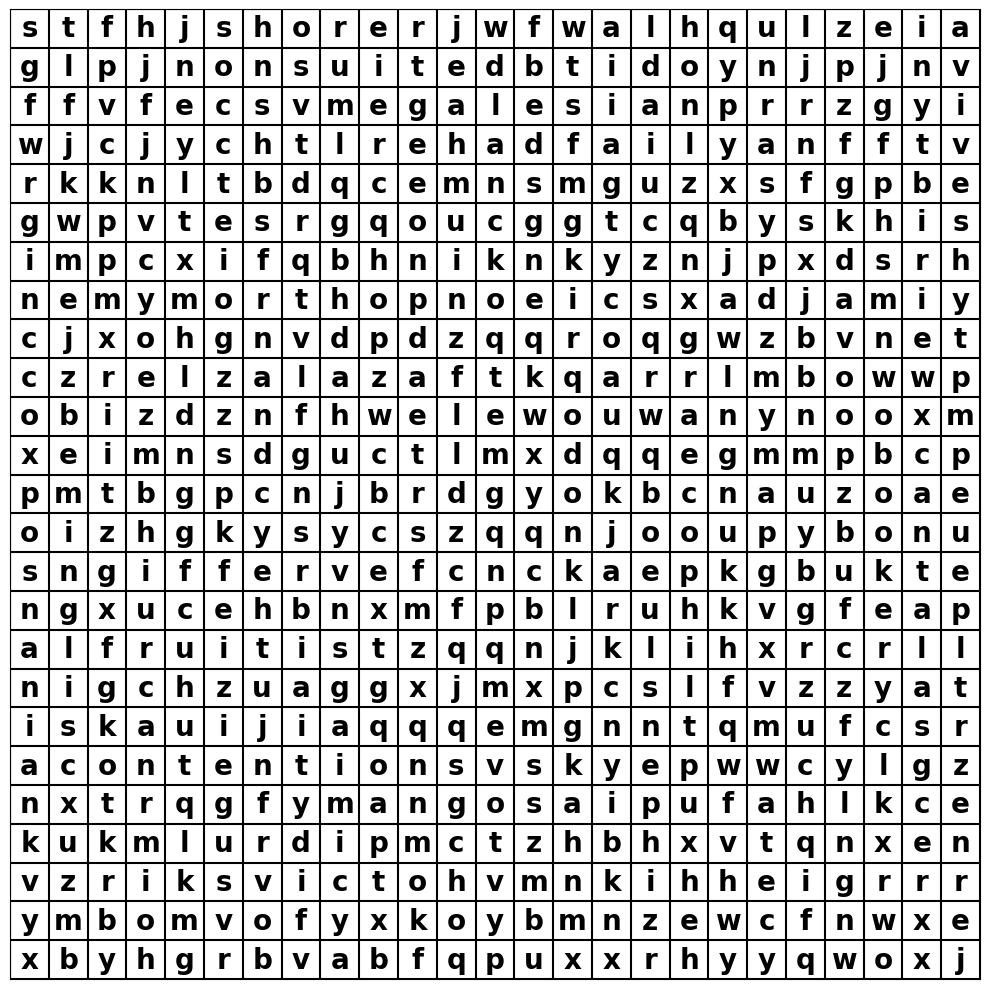

mangos
shorer
posnanian
cantalas
orthopnoeic
pufahl
fruitist
nonsuited
graecophil
inglis
megalesian
booker
avives
contentions


In [221]:
board = np.full(shape=(N, N), fill_value="_", dtype=str)
omitted = []

# Insert the words into the board
for word in word_key:
    orientation = np.random.random()
    vertical = orientation > 0.5

    if vertical:
        max_x = N - 1
        max_y = N - len(word)
    else: # Horizontal
        max_x = N - len(word)
        max_y = N - 1

    # Random word coordinates
    x = np.random.randint(0, max_x+1)
    y = np.random.randint(0, max_y+1)
    x_check = x
    y_check = y

    # Determine if the randomized coordinates produce an intersection
    intersection = False
    for i in range(len(word)):
        if board[y_check][x_check] != "_":
            intersection = True

        if vertical:
            y_check += 1
        else:
            x_check += 1

    # Word insertion based on intersection
    if not intersection:
        for letter in word:
            board[y][x] = letter
            if vertical:
                y += 1
            else:
                x += 1
    else:
        # Find first empty column
        new_x = -1
        new_y = -1
        if vertical:
            new_y = np.random.randint(0, max_y+1)
            for i in range(len(board)):
                col_counts = [1 if board[j][i] == "_" else 0 for j in range(len(board[i]))]
                col_sum = np.sum(col_counts)

                if col_sum == N:
                    new_x = i
                    break
        # Find first empty row
        else:
            new_x = np.random.randint(0, max_x+1)
            for i in range(len(board)):
                row_counts = [1 if board[i][j] == "_" else 0 for j in range(len(board[i]))]
                row_sum = np.sum(row_counts)

                if row_sum == N:
                    new_y = i
                    break

        if new_x != -1 and new_y != -1:
            for letter in word:
                board[new_y][new_x] = letter
                if vertical:
                    new_y += 1
                else:
                    new_x += 1
        else:
            omitted.append(word)

# Remove omitted from word_key
for omit in omitted:
    word_key.remove(omit)

# Fill the remaining board with random characters
for i in range(len(board)):
    for j in range(len(board[i])):
        if board[i][j] == "_":
            random_ascii = np.random.randint(97, 123)
            board[i][j] = chr(random_ascii)

plot_board(board)
print_key(word_key)

## Searching for Words

Now for the fun! Blow I explain the algorithm concepts in more detail, but for now here is the general procedure:
1. Pre-compute the coordinate location for each letter in the alphabet
2. For each word in the word key, check the directions to see if the word is at the position

#### 1. Precomputing Word Coordinates

Precomputing word coordinates is a pre-processing technique. Because the board size is $NxN$, any word search by looping through all board positions would require a time complexity of $O(N^2)$ before the depth first search starts! This is inefficient. By precomputing the letter positions, it shrinks the search space by considering only the first letter in the word (hence we only need to loop over the known positions of the first letter). This reduces the time complexity by a factor of $N$.

While the preprocessing takes a running time of $O(N^2)$ it helps save time letter when running the word search.

In [222]:
board_coordinates = {}
for i in range(len(board)):
    for j in range(len(board[i])):
        existing = board_coordinates.get(board[j][i], set())
        existing.add((i,j))
        board_coordinates[board[j][i]] = existing

Now that the positions of the letters have been identified, lets see their locations. The plot below highlights the letters $a$ in the board.

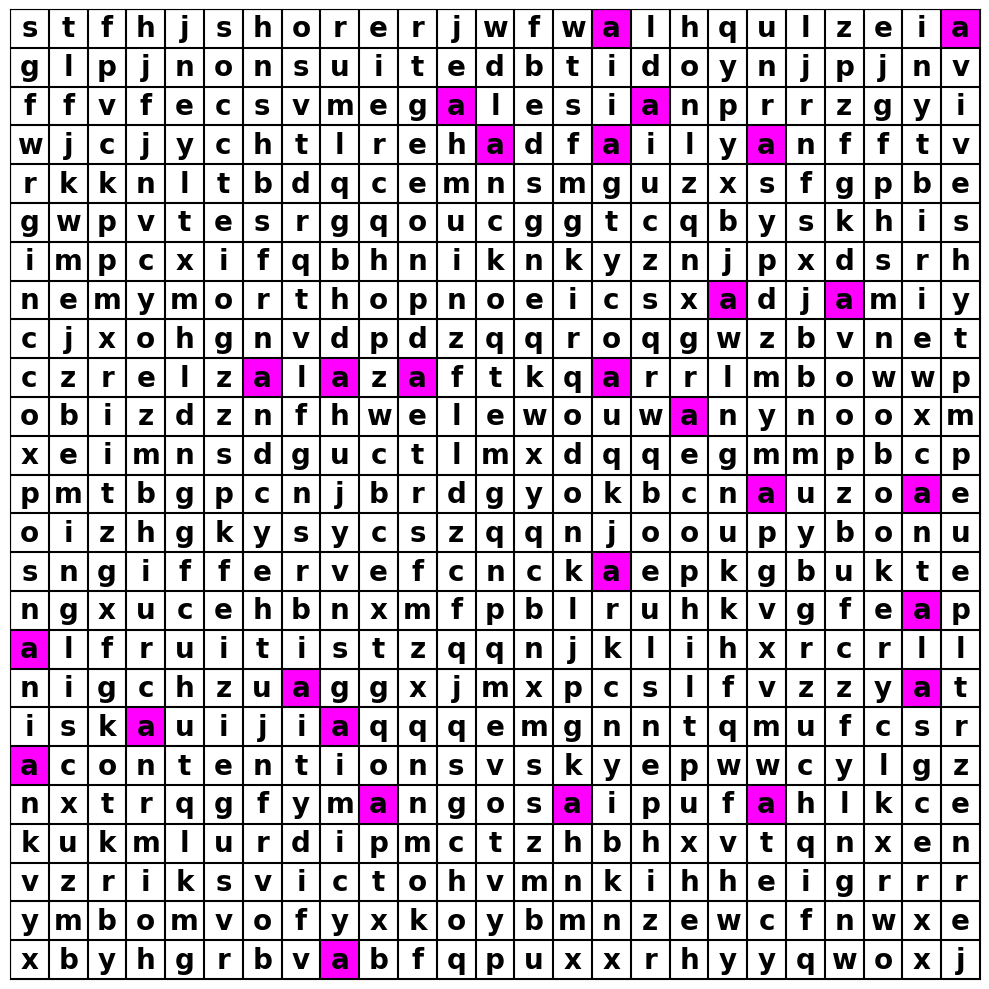

In [223]:
plot_board(board, board_coordinates.get('a', set()))

#### 2. Word Search

Now that we have the coordinates for each letter, we only need to run a search starting at the coordinates of the first letter in the word. The word can be in a horizonatal or vertical direction. Because there is no branching and the word is in a straight line of cells, iteration is the most efficient way to process the words.

Given the coordinates of the starting letter, all directions are checked to see if the word exists in that path (subject to board size constraints). The time complexity of the algorithm is $O(kcm)$ where $k$ is the number of words in the word key, $c$ are the number of coordinates for the first letter in the search word, and $m$ is the length of the search word.

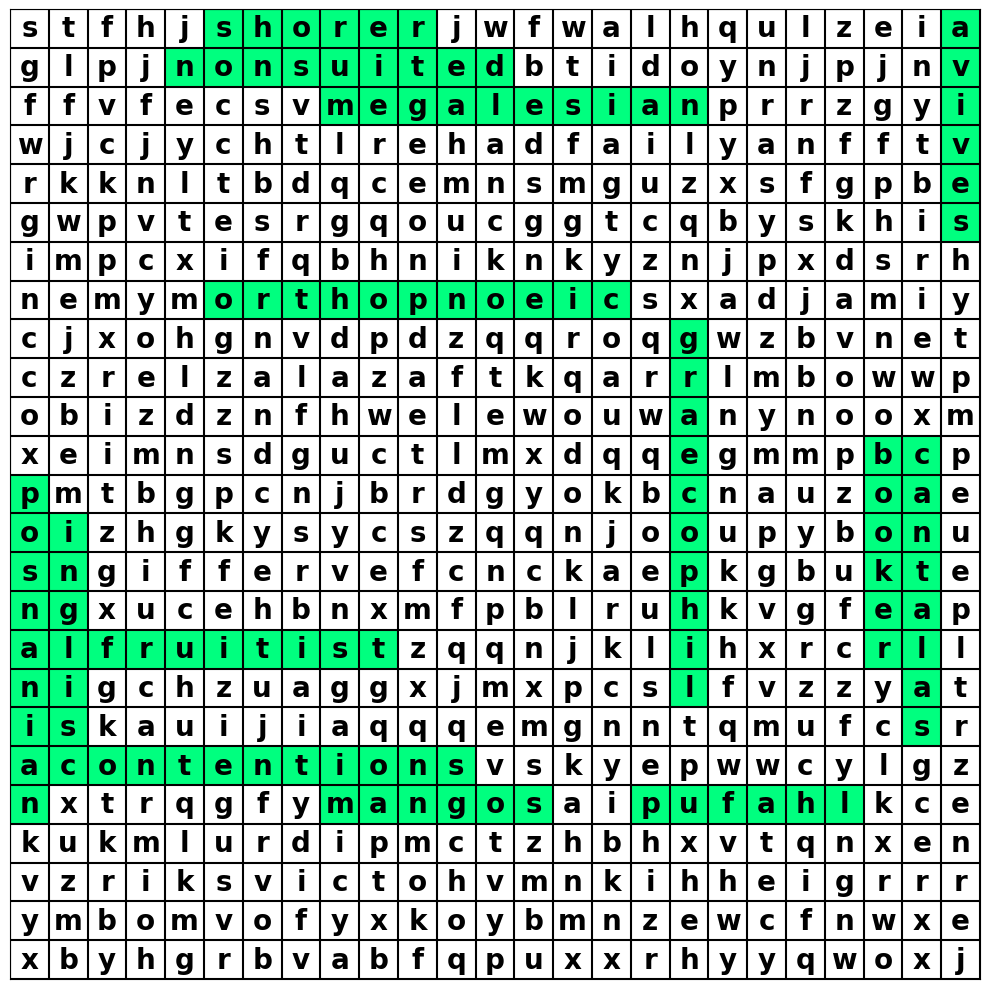

mangos
shorer
posnanian
cantalas
orthopnoeic
pufahl
fruitist
nonsuited
graecophil
inglis
megalesian
booker
avives
contentions


In [224]:
word_locations = {}

for word in word_key:
    word_coordinates = board_coordinates.get(word[0], set())

    for coordinate in word_coordinates:
        x = coordinate[0]
        y = coordinate[1]

        u_y = y # Up direction y
        d_x = x # Down x
        d_y = y # Down direction y
        l_x = x # Left direction x
        r_x = x # Right direction x

        up_coords = []
        dn_coords = []
        lt_coords = []
        rt_coords = []

        for i in range(len(word)):
            # Up
            if u_y >= 0 and board[u_y][x] == word[i]:
                up_coords.append((x,u_y))
                u_y -= 1

            # Down
            if d_y <= N-1 and (board[d_y][d_x] == word[i]):
                dn_coords.append((d_x,d_y))
                d_y += 1

            # Left
            if l_x >= 0 and board[y][l_x] == word[i]:
                lt_coords.append((l_x,y))
                l_x -= 1

            # Right
            if r_x <= N-1 and board[y][r_x] == word[i]:
                rt_coords.append((r_x,y))
                r_x += 1

        # Add the coordinates for the word
        if len(up_coords) == len(word):
            word_locations[word] = set(up_coords)
        elif len(dn_coords) == len(word):
            word_locations[word] = set(dn_coords)
        elif len(lt_coords) == len(word):
            word_locations[word] = set(lt_coords)
        elif len(rt_coords) == len(word):
            word_locations[word] = set(rt_coords)

coordinate_set = set()
for k, v in word_locations.items():
    coordinate_set.update(v)

plot_board(board, coordinate_set, highlight="springgreen")
print_key(word_key)